#**Project 9: Optimizer Comparison Using a Neural Network**


**Description:**
Students will build a simple neural network using the Iris dataset and compare the performance of different optimization algorithms. The project introduces commonly used optimizers such as Stochastic Gradient Descent and Adam.


**Task 1:** Build a simple neural network using the Iris classification dataset.


**Task 2:** Train the model using SGD and Adam optimizers.


**Task 3:** Compare the training results and classification performance.


**Expected Output/Result:**


Students will compare the performance of SGD and Adam and identify differences in training behavior and model accuracy.

#1. Import libraries and load the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

#2. Prepare the Iris dataset


In [2]:
iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X_train.shape[1])
print("Number of classes:", len(iris.target_names))

Training samples: 120
Testing samples: 30
Number of features: 4
Number of classes: 3


#3. Build the neural network

In [3]:
class IrisNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.network(x)

#4. Define the training function

In [4]:
def train_model(optimizer_name, epochs=100):

    torch.manual_seed(42)

    model = IrisNN()

    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "SGD":
        optimizer = optim.SGD(
            model.parameters(),
            lr=0.01
        )

    elif optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=0.01
        )

    losses = []
    accuracies = []

    for epoch in range(epochs):

        model.train()

        outputs = model(X_train)

        loss = criterion(outputs, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        model.eval()

        with torch.no_grad():
            predictions = model(X_train).argmax(dim=1)

            accuracy = (
                predictions == y_train
            ).float().mean().item()

        accuracies.append(accuracy)

    return model, losses, accuracies

#5. Train using SGD and Adam

In [5]:
sgd_model, sgd_losses, sgd_accuracies = train_model(
    "SGD"
)

adam_model, adam_losses, adam_accuracies = train_model(
    "Adam"
)

print("SGD training completed.")
print("Adam training completed.")

SGD training completed.
Adam training completed.


#6. Compare training loss

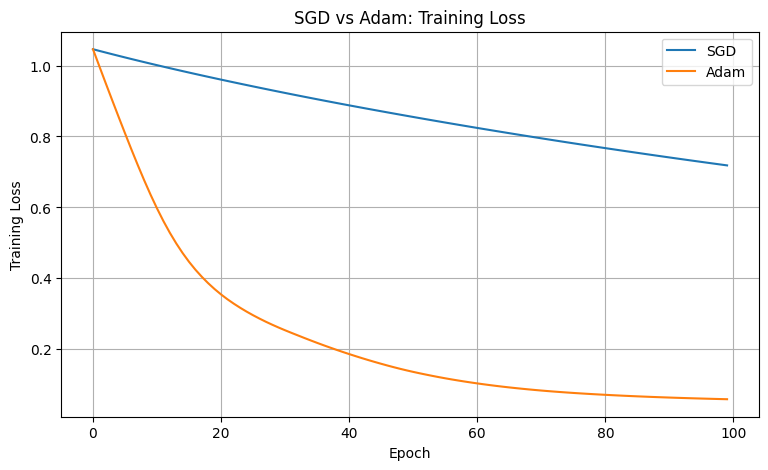

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(sgd_losses, label="SGD")
plt.plot(adam_losses, label="Adam")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("SGD vs Adam: Training Loss")
plt.legend()
plt.grid(True)
plt.show()

#7. Compare training accuracy

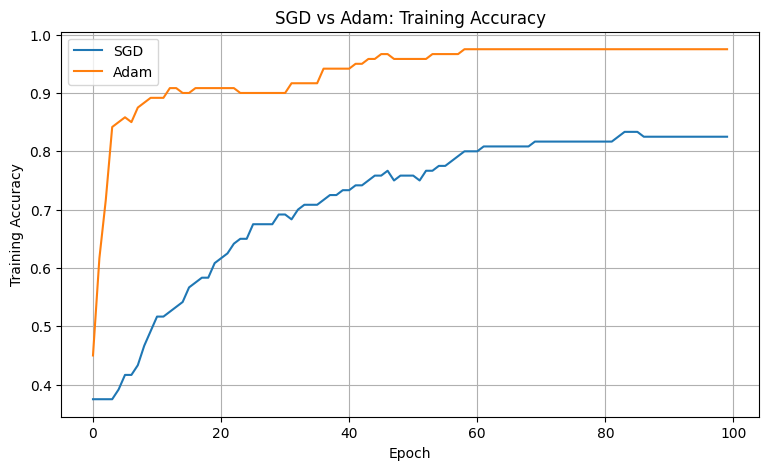

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(sgd_accuracies, label="SGD")
plt.plot(adam_accuracies, label="Adam")

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("SGD vs Adam: Training Accuracy")
plt.legend()
plt.grid(True)
plt.show()

#8. Evaluate both models on test data

In [8]:
sgd_model.eval()
adam_model.eval()

with torch.no_grad():

    sgd_predictions = sgd_model(X_test).argmax(dim=1)
    adam_predictions = adam_model(X_test).argmax(dim=1)

sgd_accuracy = accuracy_score(
    y_test.numpy(),
    sgd_predictions.numpy()
)

adam_accuracy = accuracy_score(
    y_test.numpy(),
    adam_predictions.numpy()
)

results = pd.DataFrame({
    "Optimizer": ["SGD", "Adam"],
    "Final Training Loss": [
        sgd_losses[-1],
        adam_losses[-1]
    ],
    "Training Accuracy": [
        sgd_accuracies[-1],
        adam_accuracies[-1]
    ],
    "Test Accuracy": [
        sgd_accuracy,
        adam_accuracy
    ]
})

print(results.to_string(index=False))

Optimizer  Final Training Loss  Training Accuracy  Test Accuracy
      SGD             0.718453              0.825       0.666667
     Adam             0.059045              0.975       0.966667


#9. Classification reports

In [9]:
print("SGD Classification Report")
print(
    classification_report(
        y_test.numpy(),
        sgd_predictions.numpy(),
        target_names=iris.target_names,
        zero_division=0
    )
)

print("Adam Classification Report")
print(
    classification_report(
        y_test.numpy(),
        adam_predictions.numpy(),
        target_names=iris.target_names,
        zero_division=0
    )
)

SGD Classification Report
              precision    recall  f1-score   support

      setosa       0.77      1.00      0.87        10
  versicolor       0.50      0.10      0.17        10
   virginica       0.60      0.90      0.72        10

    accuracy                           0.67        30
   macro avg       0.62      0.67      0.59        30
weighted avg       0.62      0.67      0.59        30

Adam Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



#10. Expected observations and conclusion

In [10]:
results = pd.DataFrame({
    "Criterion": [
        "Full name",
        "Learning rate",
        "Training behavior",
        "Hyperparameter sensitivity",
        "Computational cost",
        "Accuracy"
    ],
    "SGD": [
        "Stochastic Gradient Descent",
        "Fixed learning rate",
        "May converge more gradually",
        "Can be sensitive to learning rate",
        "Generally simpler per update",
        "Depends on training settings"
    ],
    "Adam": [
        "Adaptive Moment Estimation",
        "Adaptive parameter-wise updates",
        "Often converges faster initially",
        "Often easier to tune",
        "Maintains additional optimizer state",
        "Depends on training settings"
    ]
})

print("Optimizer Comparison: SGD vs Adam\n")
print(results.to_string(index=False))

print(
    "\nNote: Actual performance depends on the learning rate, "
    "number of epochs, initialization, and train-test split. "
    "Adam does not always achieve higher test accuracy than SGD. "
    "Use the experimental results to support your conclusion."
)

Optimizer Comparison: SGD vs Adam

                 Criterion                               SGD                                 Adam
                 Full name       Stochastic Gradient Descent           Adaptive Moment Estimation
             Learning rate               Fixed learning rate      Adaptive parameter-wise updates
         Training behavior       May converge more gradually     Often converges faster initially
Hyperparameter sensitivity Can be sensitive to learning rate                 Often easier to tune
        Computational cost      Generally simpler per update Maintains additional optimizer state
                  Accuracy      Depends on training settings         Depends on training settings

Note: Actual performance depends on the learning rate, number of epochs, initialization, and train-test split. Adam does not always achieve higher test accuracy than SGD. Use the experimental results to support your conclusion.


This project compared SGD and Adam using a neural network trained on the Iris dataset. Both optimizers learned to classify the three Iris species. The loss and accuracy graphs showed differences in their training behavior. Adam uses adaptive learning rates for individual parameters and may converge faster, while SGD uses a fixed learning rate. The final test accuracies were compared to determine which optimizer performed better in this experiment.